In [6]:
import os
import pandas as pd

# Use the folder where this notebook is opened
print("Current folder:", os.getcwd())

# Show the files available to the notebook
print(os.listdir())

Current folder: /Users/kymberlypatino/Desktop/PADRES
['Padres-Payroll-2025.xlsx', 'fangraphs-leaderboards (17).csv', 'fangraphs-leaderboards (16).csv', 'Padres_Salary_vs_WAR.png', '.DS_Store', 'Padres-Payroll-2024.xlsx', 'Padres_220M_Budget.png', 'Padres_Final_Dataset_2021_2025.csv', 'Padres_Combined_WAR_2021_2025.csv', 'fangraphs-leaderboards (20).csv', 'Padres_Payroll_vs_Budget.png', 'Padres-Payroll-2023.xlsx', 'fangraphs-leaderboards (11).csv', 'Padres-Payroll-2022.xlsx', 'fangraphs-leaderboards (13).csv', 'Padres-Payroll-2021.xlsx', 'Padres_Player_Value_2021_2025.csv', 'Padres_Hitters_vs_Pitchers.csv', 'fangraphs-leaderboards (12).csv', 'fangraphs-leaderboards (19).csv', '.ipynb_checkpoints', 'SDPadresProject.ipynb', 'fangraphs-leaderboards (15).csv', 'Padres_Yearly_Summary.csv', 'fangraphs-leaderboards (14).csv', 'Padres_220M_Budget.csv', 'fangraphs-leaderboards (18).csv']


In [2]:
#ONLY DO THIS CELL IF YOU HAVE A MAC AND SAME FOLDER PATH. IF NOT, SKIP THIS CODE CHUNK
import os
import pandas as pd

# Set the folder containing your Padres datasets
folder_path = "/Users/kymberlypatino/Desktop/PADRES"

# Change Jupyter's working directory
os.chdir(folder_path)

# Confirm the folder location
print("Current folder:", os.getcwd())

# Show all files in the folder
print(os.listdir())


Current folder: /Users/kymberlypatino/Desktop/PADRES
['Padres-Payroll-2025.xlsx', 'fangraphs-leaderboards (17).csv', 'fangraphs-leaderboards (16).csv', 'Padres_Salary_vs_WAR.png', '.DS_Store', 'Padres-Payroll-2024.xlsx', 'Padres_220M_Budget.png', 'Padres_Final_Dataset_2021_2025.csv', 'Padres_Combined_WAR_2021_2025.csv', 'fangraphs-leaderboards (20).csv', 'Padres_Payroll_vs_Budget.png', 'Padres-Payroll-2023.xlsx', 'fangraphs-leaderboards (11).csv', 'Padres-Payroll-2022.xlsx', 'fangraphs-leaderboards (13).csv', 'Padres-Payroll-2021.xlsx', 'Padres_Player_Value_2021_2025.csv', 'Padres_Hitters_vs_Pitchers.csv', 'fangraphs-leaderboards (12).csv', 'fangraphs-leaderboards (19).csv', '.ipynb_checkpoints', 'SDPadresProject.ipynb', 'fangraphs-leaderboards (15).csv', 'Padres_Yearly_Summary.csv', 'fangraphs-leaderboards (14).csv', 'Padres_220M_Budget.csv', 'fangraphs-leaderboards (18).csv']


In [7]:
import pandas as pd

# Batting files
batting_files = {
    2021: "fangraphs-leaderboards (11).csv",
    2022: "fangraphs-leaderboards (12).csv",
    2023: "fangraphs-leaderboards (13).csv",
    2024: "fangraphs-leaderboards (14).csv",
    2025: "fangraphs-leaderboards (15).csv"
}

# Pitching files (confirm these match the years)
pitching_files = {
    2021: "fangraphs-leaderboards (16).csv",
    2022: "fangraphs-leaderboards (17).csv",
    2023: "fangraphs-leaderboards (18).csv",
    2024: "fangraphs-leaderboards (19).csv",
    2025: "fangraphs-leaderboards (20).csv"
}

# Function to import files
def load_data(files, player_type):
    datasets = []

    for year, filename in files.items():
        df = pd.read_csv(filename)

        df["Year"] = year
        df["Player_Type"] = player_type

        datasets.append(df)

    return pd.concat(datasets, ignore_index=True)

# Import batting and pitching data
padres_batting = load_data(batting_files, "Batter")
padres_pitching = load_data(pitching_files, "Pitcher")

print("Batting records:", len(padres_batting))
print("Pitching records:", len(padres_pitching))


Batting records: 266
Pitching records: 148


In [8]:
# Keep the important columns
columns = ["Name", "Year", "Team", "WAR", "PlayerId", "Player_Type"]

batting_clean = padres_batting[columns].copy()
pitching_clean = padres_pitching[columns].copy()

# Combine batting and pitching
padres_all = pd.concat(
    [batting_clean, pitching_clean],
    ignore_index=True
)

# Rename columns
padres_all = padres_all.rename(columns={
    "Name": "Player",
    "PlayerId": "Player_ID"
})

# Convert WAR to numbers
padres_all["WAR"] = pd.to_numeric(
    padres_all["WAR"], errors="coerce"
)

# Keep Padres records
padres_all = padres_all[
    padres_all["Team"] == "SDP"
].copy()

# Display the combined dataset
padres_all.head()


,Player,Year,Team,WAR,Player_ID,Player_Type
0,Fernando Tatis Jr.,2021,SDP,6.817288,19709,Batter
1,Manny Machado,2021,SDP,4.478407,11493,Batter
2,Jake Cronenworth,2021,SDP,3.741009,18036,Batter
3,Trent Grisham,2021,SDP,2.548693,18564,Batter
4,Wil Myers,2021,SDP,2.198753,10047,Batter


In [9]:
# Total records
print("Total records:", len(padres_all))

# Records by year and player type
print(
    padres_all.groupby(
        ["Year", "Player_Type"]
    ).size()
)

# Check missing values
print(padres_all.isnull().sum())

# Check duplicate player records
print(
    padres_all.duplicated(
        subset=["Player_ID", "Year", "Player_Type"]
    ).sum()
)


Total records: 414
Year  Player_Type
2021  Batter         54
      Pitcher        34
2022  Batter         55
      Pitcher        30
2023  Batter         56
      Pitcher        30
2024  Batter         49
      Pitcher        26
2025  Batter         52
      Pitcher        28
dtype: int64
Player         0
Year           0
Team           0
WAR            0
Player_ID      0
Player_Type    0
dtype: int64
0


In [10]:
# Combine batting and pitching WAR for each player-season
padres_war = (
    padres_all
    .groupby(
        ["Player_ID", "Player", "Year"],
        as_index=False
    )
    .agg(
        WAR=("WAR", "sum")
    )
)

# Display the result
padres_war.head()


,Player_ID,Player,Year,WAR
0,2136,David Peralta,2024,0.467563
1,2434,Nelson Cruz,2023,-0.271166
2,2859,Ross Detwiler,2021,-0.261017
3,2967,Tommy Pham,2021,1.043366
4,3269,Robinson Canó,2022,-0.506009


In [11]:
# Export to CSV
padres_war.to_csv(
    "Padres_Combined_WAR_2021_2025.csv",
    index=False
)

print("Combined WAR dataset saved!")


Combined WAR dataset saved!


In [12]:
#PAYROLL DATA

In [13]:
# Load Padres payroll files from 2021–2025

payroll_files = {
    2021: "Padres-Payroll-2021.xlsx",
    2022: "Padres-Payroll-2022.xlsx",
    2023: "Padres-Payroll-2023.xlsx",
    2024: "Padres-Payroll-2024.xlsx",
    2025: "Padres-Payroll-2025.xlsx"
}

# Inspect the structure of the 2025 payroll file
excel_file = pd.ExcelFile(payroll_files[2025])

# Show worksheet names
print(excel_file.sheet_names)


['Guaranteed', 'Eligible For Arb', 'Not Yet Eligible For Arb', 'No Longer On 40-Man Roster', 'Other Payments', 'Luxury Tax Payroll Estimate']


In [14]:
# Load the first worksheet
payroll_2025 = pd.read_excel(
    payroll_files[2025],
    sheet_name=0
)

# Display the first 10 rows
display(payroll_2025.head(10))

# Display column names
print(payroll_2025.columns.tolist())


,Player,Age,Service Time,Contract,Info,AAV,2025,2026,2027,2028,2029,2030,2031,playerId
0,Manny Machado,34.3,12.056,"11 yr, $350M (2023-33)",NaN,"$31,818,182","$17,090,909","$25,090,909","$39,090,909","$39,090,909","$39,090,909","$39,090,909","$39,090,909",11493.0
1,Xander Bogaerts,34.0,11.042,"11 yr, $280M (2023-33)",NaN,"$25,454,545","$25,454,545","$25,454,545","$25,454,545","$25,454,545","$25,454,545","$25,454,545","$25,454,545",12161.0
2,Fernando Tatis Jr.,27.8,5.120,"14 yr, $338.251M (2021-34)",NaN,"$24,285,714","$20,714,286","$20,714,286","$25,714,286","$25,714,286","$36,714,286","$36,714,286","$36,714,286",19709.0
3,Joe Musgrove,33.9,8.063,"5 yr, $100M (2023-27)",NaN,"$20,000,000","$20,000,000","$20,000,000","$20,000,000",FREE AGENT,NaN,NaN,NaN,12970.0
4,Yu Darvish,40.2,12.146,"6 yr, $93M (2023-28)",NaN,"$18,000,000","$21,000,000","$1,000,000","$15,000,000","$15,000,000",FREE AGENT,NaN,NaN,13074.0
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Nick Pivetta,33.7,6.166,"3 yr, $41M (2025-28), 2027 club option; can op...",NaN,"$13,750,000","$2,500,000","$20,500,000","$14,000,000","$18,000,000",NaN,NaN,NaN,15454.0
7,Jake Cronenworth,32.7,5.000,"7 yr, $80M (2024-30)",NaN,"$11,428,571","$11,285,714","$12,285,714","$12,285,714","$12,285,714","$12,285,714","$12,285,714",FREE AGENT,18036.0
8,Robert Suarez,35.6,3.000,"3 yr, $30M (2023-25)",NaN,"$9,200,000","$10,000,000",NaN,NaN,FREE AGENT,NaN,NaN,NaN,30115.0
9,Michael King,31.4,5.004,"1 yr, $7.75M (2025)",NaN,"$7,750,000","$4,000,000","$15,000,000",NaN,NaN,NaN,NaN,NaN,19853.0


['Player', 'Age', 'Service Time', 'Contract', 'Info', 'AAV', 2025, 2026, 2027, 2028, 2029, 2030, 2031, 'playerId']


In [14]:
#Import and clean all payroll data

In [16]:
import pandas as pd

# Payroll files for 2021–2025
payroll_files = {
    2021: "Padres-Payroll-2021.xlsx",
    2022: "Padres-Payroll-2022.xlsx",
    2023: "Padres-Payroll-2023.xlsx",
    2024: "Padres-Payroll-2024.xlsx",
    2025: "Padres-Payroll-2025.xlsx"
}

# Salary categories we want
salary_sheets = [
    "Guaranteed",
    "Eligible For Arb",
    "Not Yet Eligible For Arb",
    "No Longer On 40-Man Roster"
]

payroll_data = []

# Loop through each year
for year, filename in payroll_files.items():

    # Find worksheets that actually exist
    excel_file = pd.ExcelFile(filename)

    print(f"\nProcessing {year}")
    print("Available sheets:", excel_file.sheet_names)

    for sheet in salary_sheets:

        # Skip worksheets that don't exist
        if sheet not in excel_file.sheet_names:
            print(f"Skipping missing sheet: {sheet}")
            continue

        # Read the worksheet
        df = pd.read_excel(
            excel_file,
            sheet_name=sheet
        )

        # Check required columns
        required = ["Player", "playerId", year]

        if not all(col in df.columns for col in required):
            print(f"Skipping {sheet}: missing columns")
            continue

        # Keep important columns
        df = df[required].copy()

        # Rename columns
        df.columns = [
            "Player",
            "Player_ID",
            "Salary"
        ]

        # Add year and contract category
        df["Year"] = year
        df["Contract_Type"] = sheet

        # Clean salary values
        df["Salary"] = (
            df["Salary"]
            .astype(str)
            .str.replace("$", "", regex=False)
            .str.replace(",", "", regex=False)
        )

        df["Salary"] = pd.to_numeric(
            df["Salary"],
            errors="coerce"
        )

        # Clean player IDs
        df["Player_ID"] = pd.to_numeric(
            df["Player_ID"],
            errors="coerce"
        )

        # Remove missing values
        df = df.dropna(
            subset=["Player_ID", "Salary"]
        )

        # Keep positive salaries
        df = df[df["Salary"] > 0]

        payroll_data.append(df)

# Combine all payroll records
padres_payroll = pd.concat(
    payroll_data,
    ignore_index=True
)

# Convert player IDs to integers
padres_payroll["Player_ID"] = (
    padres_payroll["Player_ID"].astype(int)
)

# Display results
print("\nTotal payroll records:", len(padres_payroll))

display(padres_payroll.head(10))




Processing 2021
Available sheets: ['Guaranteed', 'Eligible For Arb', 'Not Yet Eligible For Arb', 'No Longer On 40-Man Roster', 'Other Payments', 'Other Luxury Tax Payments', 'Luxury Tax Payroll Estimate']

Processing 2022
Available sheets: ['Guaranteed', 'Eligible For Arb', 'Not Yet Eligible For Arb', 'No Longer On 40-Man Roster', 'Other Payments', 'Other Luxury Tax Payments', 'Luxury Tax Payroll Estimate']

Processing 2023
Available sheets: ['Guaranteed', 'Eligible For Arb', 'Not Yet Eligible For Arb', 'No Longer On 40-Man Roster', 'Other Payments', 'Other Luxury Tax Payments', 'Luxury Tax Payroll Estimate']

Processing 2024
Available sheets: ['Guaranteed', 'Eligible For Arb', 'Not Yet Eligible For Arb', 'Other Payments', 'Other Luxury Tax Payments', 'Luxury Tax Payroll Estimate']
Skipping missing sheet: No Longer On 40-Man Roster

Processing 2025
Available sheets: ['Guaranteed', 'Eligible For Arb', 'Not Yet Eligible For Arb', 'No Longer On 40-Man Roster', 'Other Payments', 'Luxury T

,Player,Player_ID,Salary,Year,Contract_Type
0,Manny Machado,11493,32000000.0,2021,Guaranteed
1,Fernando Tatis Jr.,19709,1714286.0,2021,Guaranteed
2,Yu Darvish,13074,23000000.0,2021,Guaranteed
3,Eric Hosmer,3516,20625000.0,2021,Guaranteed
4,Wil Myers,10047,22500000.0,2021,Guaranteed
5,Blake Snell,13543,11100000.0,2021,Guaranteed
6,Drew Pomeranz,11426,8000000.0,2021,Guaranteed
7,Ha-Seong Kim,27506,5000000.0,2021,Guaranteed
8,Jurickson Profar,10815,6000000.0,2021,Guaranteed
9,Mike Clevinger,12808,3500000.0,2021,Guaranteed


In [ ]:
#Check for duplicates

In [18]:
# Check for duplicate player-year records
duplicates = padres_payroll[
    padres_payroll.duplicated(
        subset=["Player_ID", "Year"],
        keep=False
    )
]

print("Duplicate records:", len(duplicates))

display(
    duplicates.sort_values(["Year", "Player_ID"])
)



Duplicate records: 0


,Player,Player_ID,Salary,Year,Contract_Type


In [ ]:
#Merge Payroll with WAR

In [19]:
# Make sure player IDs are integers
padres_war["Player_ID"] = padres_war["Player_ID"].astype(int)

# Merge payroll with batting and pitching WAR
padres_final = pd.merge(
    padres_war,
    padres_payroll[
        ["Player_ID", "Year", "Salary", "Contract_Type"]
    ],
    on=["Player_ID", "Year"],
    how="inner",
    validate="one_to_one"
)

# Convert salary to millions
padres_final["Salary_Millions"] = (
    padres_final["Salary"] / 1_000_000
)

# Display results
print("Matched player-season records:", len(padres_final))

display(padres_final.head(10))


Matched player-season records: 151


,Player_ID,Player,Year,WAR,Salary,Contract_Type,Salary_Millions
0,2136,David Peralta,2024,0.467563,800000.0,Guaranteed,0.800000
1,2434,Nelson Cruz,2023,-0.271166,1000000.0,No Longer On 40-Man Roster,1.000000
2,2859,Ross Detwiler,2021,-0.261017,61344.0,Guaranteed,0.061344
3,2967,Tommy Pham,2021,1.043366,8900000.0,Eligible For Arb,8.900000
4,3269,Robinson Canó,2022,-0.506009,80769.0,No Longer On 40-Man Roster,0.080769
5,3516,Eric Hosmer,2021,0.872504,20625000.0,Guaranteed,20.625000
6,4153,Jake Arrieta,2021,-0.048650,144159.0,No Longer On 40-Man Roster,0.144159
7,4264,Mark Melancon,2021,1.062215,2000000.0,Guaranteed,2.000000
8,4806,Rich Hill,2023,-0.369950,8000000.0,Guaranteed,8.000000
9,4940,Jason Heyward,2025,-0.520155,1000000.0,No Longer On 40-Man Roster,1.000000


In [20]:
# Check missing values
print("Missing values:")
print(padres_final.isnull().sum())

# Check records by year
print("\nRecords by year:")
print(padres_final.groupby("Year").size())

# Check total salary by year
print("\nTotal matched salaries by year:")
print(
    padres_final.groupby("Year")["Salary"]
    .sum()
    .apply(lambda x: f"${x:,.2f}")
)

# Display important columns
display(
    padres_final[
        ["Player", "Year", "Salary", "WAR", "Contract_Type"]
    ].head(15)
)


Missing values:
Player_ID          0
Player             0
Year               0
WAR                0
Salary             0
Contract_Type      0
Salary_Millions    0
dtype: int64

Records by year:
Year
2021    34
2022    27
2023    30
2024    27
2025    33
dtype: int64

Total matched salaries by year:
Year
2021    $178,695,631.00
2022    $196,420,169.00
2023    $240,540,637.00
2024    $170,497,777.00
2025    $192,697,580.00
Name: Salary, dtype: object


,Player,Year,Salary,WAR,Contract_Type
0,David Peralta,2024,800000.0,0.467563,Guaranteed
1,Nelson Cruz,2023,1000000.0,-0.271166,No Longer On 40-Man Roster
2,Ross Detwiler,2021,61344.0,-0.261017,Guaranteed
3,Tommy Pham,2021,8900000.0,1.043366,Eligible For Arb
4,Robinson Canó,2022,80769.0,-0.506009,No Longer On 40-Man Roster
5,Eric Hosmer,2021,20625000.0,0.872504,Guaranteed
6,Jake Arrieta,2021,144159.0,-0.048650,No Longer On 40-Man Roster
7,Mark Melancon,2021,2000000.0,1.062215,Guaranteed
8,Rich Hill,2023,8000000.0,-0.369950,Guaranteed
9,Jason Heyward,2025,1000000.0,-0.520155,No Longer On 40-Man Roster


In [21]:
# Save the merged data
padres_final.to_csv(
    "Padres_Final_Dataset_2021_2025.csv",
    index=False
)

print("Final dataset saved successfully!")



Final dataset saved successfully!


In [ ]:
#Descriptive Statistics

In [22]:
# Summary statistics for salary and WAR
summary = padres_final[
    ["Salary_Millions", "WAR"]
].describe()

display(summary.round(2))

# Average salary and WAR by year
yearly_summary = padres_final.groupby("Year").agg(
    Average_Salary=("Salary_Millions", "mean"),
    Average_WAR=("WAR", "mean"),
    Total_WAR=("WAR", "sum"),
    Players=("Player", "count")
)

display(yearly_summary.round(2))


,Salary_Millions,WAR
count,151.00,151.00
mean,6.48,1.31
std,7.40,1.69
min,0.05,-0.90
25%,0.85,0.06
50%,3.75,0.77
75%,8.76,2.17
max,32.00,7.13


,Average_Salary,Average_WAR,Total_WAR,Players
Year,,,,
2021,5.26,1.04,35.40,34
2022,7.27,1.39,37.52,27
2023,8.02,1.45,43.50,30
2024,6.31,1.67,45.14,27
2025,5.84,1.11,36.68,33


In [ ]:
#Correlation Analysis

In [23]:
# Calculate correlation between salary and WAR
correlation = padres_final[
    "Salary_Millions"
].corr(padres_final["WAR"])

print("Salary and WAR correlation:", round(correlation, 3))


Salary and WAR correlation: 0.506


In [ ]:
#Salary vs. WAR scatterplot

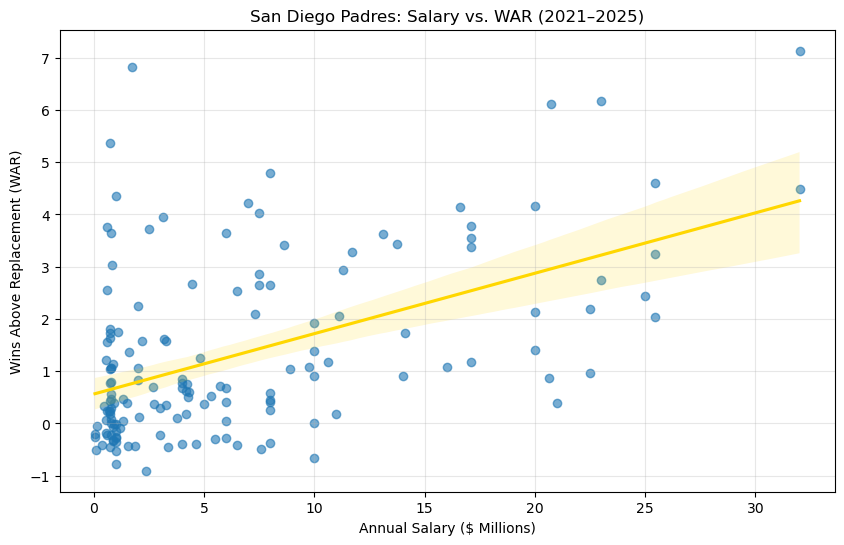

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.regplot(
    data=padres_final,
    x="Salary_Millions",
    y="WAR",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "gold"}
)

plt.title("San Diego Padres: Salary vs. WAR (2021–2025)")
plt.xlabel("Annual Salary ($ Millions)")
plt.ylabel("Wins Above Replacement (WAR)")
plt.grid(alpha=0.3)

plt.show()


In [ ]:
#Linear Regression

In [25]:
from sklearn.linear_model import LinearRegression

# Independent variable: salary
X = padres_final[["Salary_Millions"]]

# Dependent variable: WAR
y = padres_final["WAR"]

# Build regression model
model = LinearRegression()
model.fit(X, y)

# Display results
print("Intercept:", round(model.intercept_, 3))
print("Salary coefficient:", round(model.coef_[0], 3))
print("R-squared:", round(model.score(X, y), 3))


Intercept: 0.564
Salary coefficient: 0.116
R-squared: 0.256


In [ ]:
#Find the best-value players

In [26]:
# Only calculate cost per WAR for positive-WAR players
padres_value = padres_final[
    padres_final["WAR"] > 0
].copy()

# Calculate salary per WAR in millions
padres_value["Cost_Per_WAR"] = (
    padres_value["Salary_Millions"] /
    padres_value["WAR"]
)

# Show best-value players
best_value = padres_value.sort_values(
    "Cost_Per_WAR"
).head(10)

display(
    best_value[
        ["Player", "Year", "Salary_Millions", "WAR", "Cost_Per_WAR"]
    ].round(3)
)


,Player,Year,Salary_Millions,WAR,Cost_Per_WAR
141,Jackson Merrill,2024,0.740,5.362,0.138
97,Jake Cronenworth,2021,0.585,3.762,0.155
98,Jake Cronenworth,2022,0.757,3.645,0.208
26,Jurickson Profar,2024,1.000,4.355,0.230
104,Trent Grisham,2021,0.589,2.549,0.231
111,Fernando Tatis Jr.,2021,1.714,6.817,0.251
142,Jackson Merrill,2025,0.810,3.035,0.267
123,Chris Paddack,2021,0.611,1.550,0.394
134,Matt Waldron,2024,0.742,1.812,0.409
105,Trent Grisham,2022,0.729,1.726,0.423


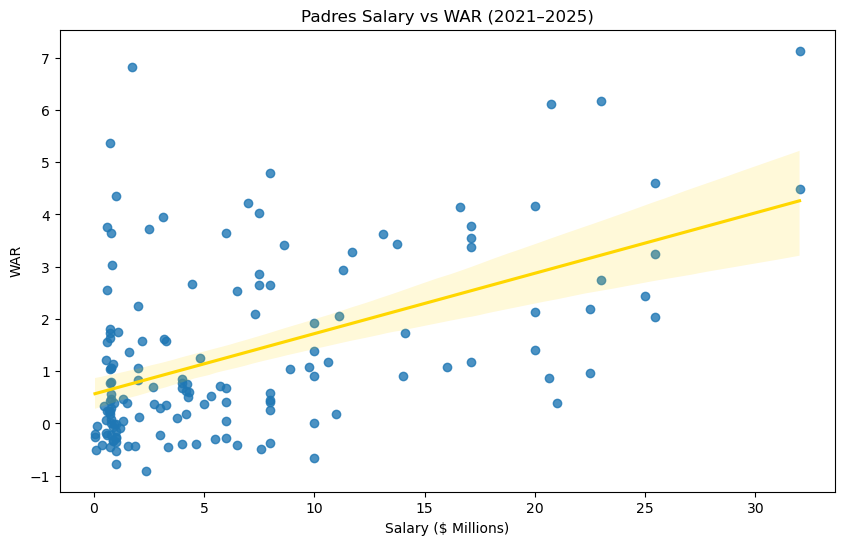

In [27]:
# Save yearly statistics
yearly_summary.to_csv("Padres_Yearly_Summary.csv")

# Save player value rankings
padres_value.to_csv(
    "Padres_Player_Value_2021_2025.csv",
    index=False
)

# Save the scatterplot
plt.figure(figsize=(10, 6))

sns.regplot(
    data=padres_final,
    x="Salary_Millions",
    y="WAR",
    line_kws={"color": "gold"}
)

plt.title("Padres Salary vs WAR (2021–2025)")
plt.xlabel("Salary ($ Millions)")
plt.ylabel("WAR")

plt.savefig(
    "Padres_Salary_vs_WAR.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
#Identify the largest spending inefficiencies

In [28]:
# Find players with high salaries and low WAR

high_salary_low_war = padres_final[
    (padres_final["Salary_Millions"] >= 10) &
    (padres_final["WAR"] < 2)
].copy()

# Sort by highest salary
high_salary_low_war = high_salary_low_war.sort_values(
    "Salary_Millions",
    ascending=False
)

# Display results
display(
    high_salary_low_war[
        ["Player", "Year", "Salary_Millions", "WAR", "Contract_Type"]
    ].round(2)
)


,Player,Year,Salary_Millions,WAR,Contract_Type
22,Wil Myers,2022,22.50,0.98,Guaranteed
57,Yu Darvish,2025,21.00,0.39,Guaranteed
5,Eric Hosmer,2021,20.62,0.87,Guaranteed
52,Joe Musgrove,2024,20.00,1.41,Guaranteed
124,Juan Soto,2022,17.10,1.17,Eligible For Arb
56,Yu Darvish,2024,16.00,1.09,Guaranteed
69,Josh Hader,2023,14.10,1.73,Eligible For Arb
108,Luis Arraez,2025,14.00,0.91,Eligible For Arb
68,Josh Hader,2022,11.00,0.19,Eligible For Arb
107,Luis Arraez,2024,10.60,1.18,Eligible For Arb


In [29]:
#Compare hitters and pitchers


In [30]:
# Identify whether each player has batting or pitching data

player_roles = (
    padres_all
    .groupby(["Player_ID", "Year"])["Player_Type"]
    .agg(lambda x: ", ".join(sorted(set(x))))
    .reset_index()
)

# Add roles to our final dataset
padres_with_roles = padres_final.merge(
    player_roles,
    on=["Player_ID", "Year"],
    how="left",
    validate="one_to_one"
)

# Calculate correlations by player type
for role in ["Batter", "Pitcher"]:
    subset = padres_with_roles[
        padres_with_roles["Player_Type"] == role
    ]

    print(
        role,
        "records:", len(subset),
        "correlation:",
        round(subset["Salary_Millions"].corr(subset["WAR"]), 3)
    )
    

Batter records: 68 correlation: 0.545
Pitcher records: 0 correlation: nan


In [ ]:
#Correct Player Classification

In [31]:
# Check how player types are labeled
print(
    padres_all["Player_Type"].value_counts()
)

# Identify player-seasons with pitching records
pitcher_ids = set(
    zip(
        padres_all.loc[
            padres_all["Player_Type"] == "Pitcher", "Player_ID"
        ],
        padres_all.loc[
            padres_all["Player_Type"] == "Pitcher", "Year"
        ]
    )
)

# Assign primary player role
padres_with_roles = padres_final.copy()

padres_with_roles["Primary_Role"] = [
    "Pitcher" if (pid, year) in pitcher_ids else "Batter"
    for pid, year in zip(
        padres_with_roles["Player_ID"],
        padres_with_roles["Year"]
    )
]

# Count records and calculate correlations
for role in ["Batter", "Pitcher"]:

    subset = padres_with_roles[
        padres_with_roles["Primary_Role"] == role
    ]

    correlation = subset[
        "Salary_Millions"
    ].corr(subset["WAR"])

    print(
        role,
        "records:", len(subset),
        "correlation:", round(correlation, 3)
    )
    

Player_Type
Batter     266
Pitcher    148
Name: count, dtype: int64
Batter records: 68 correlation: 0.545
Pitcher records: 83 correlation: 0.426


In [ ]:
#Save the hitter vs pitcher results

In [32]:
# Calculate correlation by player role
role_summary = (
    padres_with_roles
    .groupby("Primary_Role")
    .agg(
        Players=("Player", "count"),
        Average_Salary=("Salary_Millions", "mean"),
        Average_WAR=("WAR", "mean")
    )
)

role_summary["Correlation"] = (
    padres_with_roles
    .groupby("Primary_Role")
    .apply(
        lambda df: df["Salary_Millions"].corr(df["WAR"]),
        include_groups=False
    )
)

display(role_summary.round(3))

# Save results
role_summary.to_csv(
    "Padres_Hitters_vs_Pitchers.csv"
)


,Players,Average_Salary,Average_WAR,Correlation
Primary_Role,,,,
Batter,68,7.210,1.666,0.545
Pitcher,83,5.886,1.023,0.426


In [ ]:
#Create the budget

Total Budget: $ 220 million


,Category,Budget_Millions,Percentage
0,Position Players,100,45.45
1,Starting Pitchers,65,29.55
2,Bullpen,25,11.36
3,Bench and Depth,15,6.82
4,Financial Flexibility,15,6.82


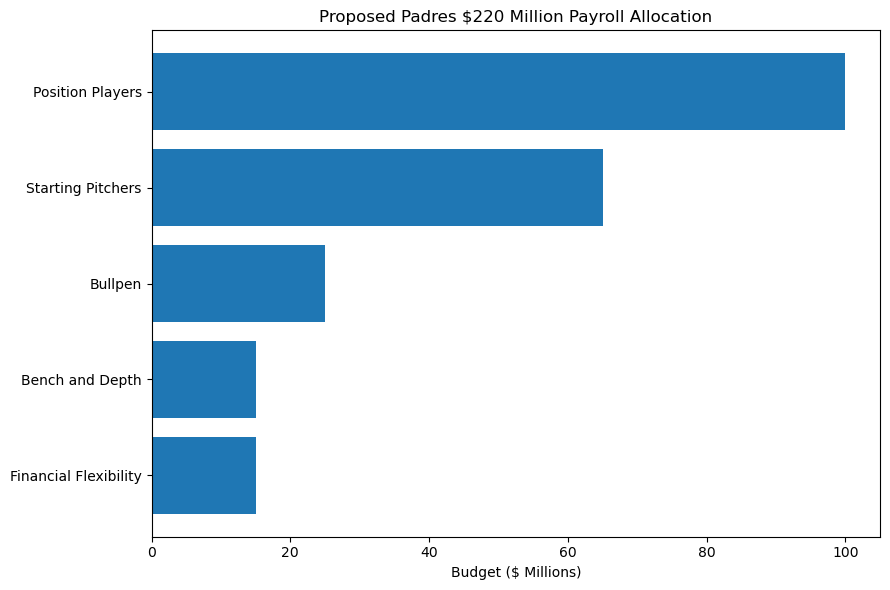

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

# Hypothetical Padres payroll allocation
budget = pd.DataFrame({
    "Category": [
        "Position Players",
        "Starting Pitchers",
        "Bullpen",
        "Bench and Depth",
        "Financial Flexibility"
    ],
    "Budget_Millions": [100, 65, 25, 15, 15]
})

# Calculate percentages
budget["Percentage"] = (
    budget["Budget_Millions"] / 220 * 100
)

print("Total Budget: $", budget["Budget_Millions"].sum(), "million")

display(budget.round(2))

# Create budget visualization
plt.figure(figsize=(9, 6))

plt.barh(
    budget["Category"],
    budget["Budget_Millions"]
)

plt.xlabel("Budget ($ Millions)")
plt.title("Proposed Padres $220 Million Payroll Allocation")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig(
    "Padres_220M_Budget.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save budget data
budget.to_csv("Padres_220M_Budget.csv", index=False)


In [ ]:
#Analyze the 2025 payroll commitments

In [34]:
# Select 2025 payroll records
payroll_2025 = padres_payroll[
    padres_payroll["Year"] == 2025
].copy()

# Calculate payroll by contract type
contract_summary = (
    payroll_2025
    .groupby("Contract_Type")
    .agg(
        Players=("Player_ID", "count"),
        Total_Salary=("Salary", "sum")
    )
    .reset_index()
)

# Convert salary to millions
contract_summary["Salary_Millions"] = (
    contract_summary["Total_Salary"] / 1_000_000
)

# Display results
display(
    contract_summary[
        ["Contract_Type", "Players", "Salary_Millions"]
    ].round(2)
)

# Calculate total recorded player salaries
total_2025 = payroll_2025["Salary"].sum() / 1_000_000

print("2025 recorded player salaries: $",
      round(total_2025, 2), "million")

print("Hypothetical budget: $220 million")

print("Difference: $",
      round(220 - total_2025, 2), "million")


,Contract_Type,Players,Salary_Millions
0,Eligible For Arb,7,44.75
1,Guaranteed,17,160.10
2,No Longer On 40-Man Roster,4,3.21
3,Not Yet Eligible For Arb,6,4.64


2025 recorded player salaries: $ 212.7 million
Hypothetical budget: $220 million
Difference: $ 7.3 million


In [ ]:
#Identify the highest-paid players in 2025

In [35]:
# Sort 2025 players by salary
top_paid_2025 = payroll_2025.sort_values(
    "Salary",
    ascending=False
).head(10).copy()

# Convert to millions
top_paid_2025["Salary_Millions"] = (
    top_paid_2025["Salary"] / 1_000_000
)

display(
    top_paid_2025[
        ["Player", "Salary_Millions", "Contract_Type"]
    ].round(2)
)


,Player,Salary_Millions,Contract_Type
123,Xander Bogaerts,25.45,Guaranteed
126,Yu Darvish,21.00,Guaranteed
124,Fernando Tatis Jr.,20.71,Guaranteed
125,Joe Musgrove,20.00,Guaranteed
122,Manny Machado,17.09,Guaranteed
139,Luis Arraez,14.00,Eligible For Arb
140,Dylan Cease,13.75,Eligible For Arb
128,Jake Cronenworth,11.29,Guaranteed
129,Robert Suarez,10.00,Guaranteed
134,Ryan O'Hearn,8.00,Guaranteed


In [ ]:
#Budget versus recorded payroll

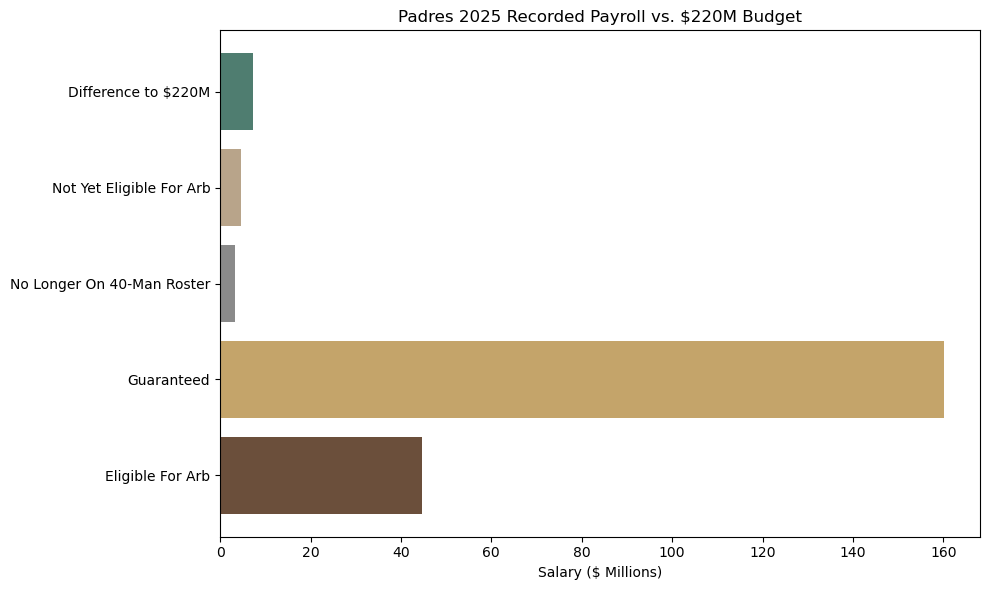

In [36]:
import matplotlib.pyplot as plt

# Use the actual contract summary
payroll_categories = contract_summary[
    ["Contract_Type", "Salary_Millions"]
].copy()

# Add remaining difference
remaining = 220 - payroll_categories["Salary_Millions"].sum()

payroll_categories.loc[len(payroll_categories)] = [
    "Difference to $220M",
    remaining
]

# Plot
plt.figure(figsize=(10, 6))

plt.barh(
    payroll_categories["Contract_Type"],
    payroll_categories["Salary_Millions"],
    color=["#6B4F3B", "#C4A46A", "#8A8A8A", "#B8A48A", "#4F7D70"]
)

plt.xlabel("Salary ($ Millions)")
plt.title("Padres 2025 Recorded Payroll vs. $220M Budget")

plt.tight_layout()

plt.savefig(
    "Padres_Payroll_vs_Budget.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
#Save the dataset and findings we have gathered

In [38]:
# Save final dataset
padres_final.to_csv(
    "Padres_Final_Dataset_2021_2025.csv",
    index=False
)

# Save yearly summary
yearly_summary.to_csv(
    "Padres_Yearly_Summary.csv"
)

# Save budget
budget.to_csv(
    "Padres_220M_Budget.csv",
    index=False
)

print("Project files saved successfully!")

        

Project files saved successfully!
